# Outlier Analysis: Cancer Severity Classification
Compare four classifiers trained on all training rows versus training rows retained by a class-wise interquartile range (IQR) filter. Both experiments use the **same untouched test set**.

This is an educational tabular classification experiment, not a validated clinical prediction system. Severity categories below are project-defined thresholds.

## Setup
Install dependencies in your Python environment:
```bash
pip install pandas numpy matplotlib seaborn scikit-learn kagglehub jupyter
```
Run the cells in order. Place `global_cancer_patients_2015_2024.csv` beside this notebook or inside `data/`. If neither exists, KaggleHub downloads [Global Cancer Patients (2015–2024)](https://www.kaggle.com/datasets/zahidmughal2343/global-cancer-patients-2015-2024). Kaggle access may require authentication or network access.

Old outputs have been cleared because they came from a different evaluation procedure. Run this notebook to obtain corrected results.

In [1]:
pip install pandas numpy matplotlib seaborn scikit-learn kagglehub jupyter


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 35.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 947.5/947.5 kB 24.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.5/77.5 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.2/60.2 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 49.3 MB/s eta 0:00:00


In [2]:
from pathlib import Path
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix, roc_curve, roc_auc_score, auc)

RANDOM_STATE = 42
TEST_SIZE = 0.20
IQR_FACTOR = 1.2
CLASSES = [0, 1, 2]
CLASS_NAMES = ['Low', 'Medium', 'High']
NUMERIC_FEATURES = ['Age', 'Genetic_Risk', 'Air_Pollution', 'Alcohol_Use',
                    'Smoking', 'Obesity_Level', 'Treatment_Cost_USD']
CATEGORICAL_FEATURES = ['Gender', 'Country_Region', 'Cancer_Type', 'Cancer_Stage']
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET = 'Target_Severity_Score'
print(f'Python {platform.python_version()} | scikit-learn {sklearn.__version__}')

Python 3.13.16 | scikit-learn 1.6.1


## 1. Load and validate the data
Use the download directory returned by KaggleHub instead of a machine-specific Kaggle path. Patient IDs and the original severity score are excluded from the predictors. Missing targets are removed; missing predictors are imputed inside each training pipeline.

In [3]:
CSV_NAME = 'global_cancer_patients_2015_2024.csv'
DATA_PATH = None  # Optionally set to Path('/your/path/to/file.csv').
if DATA_PATH is None:
    local_candidates = [Path(CSV_NAME), Path('data') / CSV_NAME]
    DATA_PATH = next((p for p in local_candidates if p.is_file()), None)
if DATA_PATH is None:
    import kagglehub
    dataset_dir = Path(kagglehub.dataset_download(
        'zahidmughal2343/global-cancer-patients-2015-2024'))
    matches = sorted(dataset_dir.rglob(CSV_NAME))
    if len(matches) != 1:
        raise FileNotFoundError(f'Expected exactly one {CSV_NAME} in {dataset_dir}.')
    DATA_PATH = matches[0]
raw_df = pd.read_csv(Path(DATA_PATH))
missing_columns = sorted(set(FEATURES + [TARGET]) - set(raw_df.columns))
if missing_columns:
    raise ValueError(f'Missing required columns: {missing_columns}')
df = raw_df[FEATURES + [TARGET]].copy()
for col in NUMERIC_FEATURES + [TARGET]:
    df[col] = pd.to_numeric(df[col], errors='raise')
df[NUMERIC_FEATURES + [TARGET]] = df[NUMERIC_FEATURES + [TARGET]].replace(
    [np.inf, -np.inf], np.nan)
missing_targets = int(df[TARGET].isna().sum())
df = df.dropna(subset=[TARGET]).reset_index(drop=True)
if df.empty:
    raise ValueError('No rows with valid targets remain.')
print(f'Loaded {len(raw_df):,} rows; removed {missing_targets:,} missing targets.')
display(df.head())
display(df.isna().sum().rename('Missing values').to_frame())

100%|██████████| 1.20M/1.20M [00:00<00:00, 50.5MB/s]

Extracting files...


Loaded 50,000 rows; removed 0 missing targets.


,Age,Genetic_Risk,Air_Pollution,Alcohol_Use,Smoking,Obesity_Level,Treatment_Cost_USD,Gender,Country_Region,Cancer_Type,Cancer_Stage,Target_Severity_Score
0,71,6.4,2.8,9.5,0.9,8.7,62913.44,Male,UK,Lung,Stage III,4.92
1,34,1.3,4.5,3.7,3.9,6.3,12573.41,Male,China,Leukemia,Stage 0,4.65
2,80,7.4,7.9,2.4,4.7,0.1,6984.33,Male,Pakistan,Breast,Stage II,5.84
3,40,1.7,2.9,4.8,3.5,2.7,67446.25,Male,UK,Colon,Stage I,3.12
4,43,5.1,2.8,2.3,6.7,0.5,77977.12,Female,Brazil,Skin,Stage III,3.62


,Missing values
Age,0
Genetic_Risk,0
Air_Pollution,0
Alcohol_Use,0
Smoking,0
Obesity_Level,0
Treatment_Cost_USD,0
Gender,0
Country_Region,0
Cancer_Type,0


## 2. Define labels and split once
The original score is converted to Low (score ≤ 3), Medium (3 < score ≤ 6), and High (score > 6). Stratification preserves approximate class proportions. Split **before** calculating IQR thresholds or fitting preprocessing. The test rows and labels are never used for training or outlier removal.

,Training,Test
Severity_Class,,
Low,2114,529
Medium,30029,7507
High,7857,1964


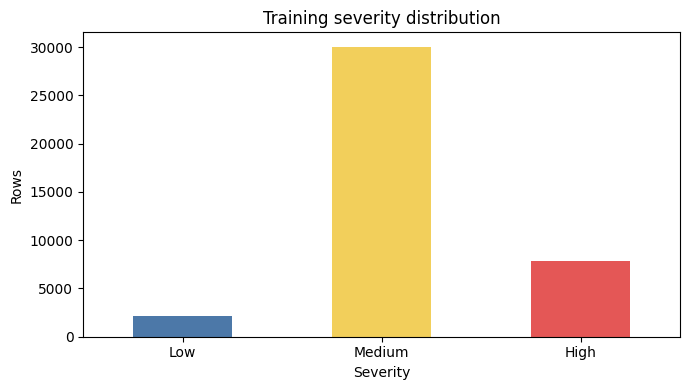

In [4]:
y = pd.Series(np.select([df[TARGET] <= 3, df[TARGET] <= 6], [0, 1], default=2),
              index=df.index, name='Severity_Class')
X = df[FEATURES].copy()
if set(y.unique()) != set(CLASSES) or y.value_counts().min() < 2:
    raise ValueError('All three classes need at least two rows for stratified splitting.')
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
assert set(X_train.index).isdisjoint(X_test.index)
display(pd.DataFrame({'Training': y_train.value_counts(),
                      'Test': y_test.value_counts()}).reindex(CLASSES).rename(
                          index=dict(zip(CLASSES, CLASS_NAMES))))
ax = y_train.value_counts().reindex(CLASSES).set_axis(CLASS_NAMES).plot.bar(
    color=['#4c78a8', '#f2cf5b', '#e45756'], figsize=(7, 4), rot=0)
ax.set(title='Training severity distribution', xlabel='Severity', ylabel='Rows')
plt.tight_layout()
plt.show()

## 3. Filter training rows using class-wise IQR
Within each **training** class, calculate Q1 and Q3 for selected numeric predictors. Remove a row if any such predictor falls outside `[Q1 − 1.2 × IQR, Q3 + 1.2 × IQR]`. Constant features (zero IQR) and missing values do not trigger removal; missing values are handled later by imputation.

This is a supervised training-data selection experiment: it uses training labels to define groups. It is not an outlier detector for unlabeled future patients. The filter considers only the actual numeric model inputs, rather than unrelated numeric columns. Filtering can disproportionately remove minority-class examples, so retention is reported.

In [5]:
def iqr_training_mask(X_fit, y_fit, numeric_columns, factor=1.2):
    """Calculate a retention mask and bounds using training data only."""
    if factor < 0 or not X_fit.index.equals(y_fit.index):
        raise ValueError('Use a nonnegative factor and aligned X/y indices.')
    keep = pd.Series(True, index=X_fit.index)
    bounds = []
    for label in sorted(y_fit.unique()):
        group = X_fit.loc[y_fit == label, numeric_columns]
        q1, q3 = group.quantile(0.25), group.quantile(0.75)
        iqr = q3 - q1
        active = iqr.notna() & (iqr > 0)
        lower, upper = q1 - factor * iqr, q3 + factor * iqr
        outside = group.lt(lower, axis='columns') | group.gt(upper, axis='columns')
        keep.loc[group.index] = ~outside.loc[:, active].any(axis=1)
        for feature in numeric_columns:
            bounds.append({'Class': label, 'Feature': feature,
                           'Lower': lower[feature], 'Upper': upper[feature],
                           'Applied': bool(active[feature])})
    return keep, pd.DataFrame(bounds)

keep_mask, iqr_bounds = iqr_training_mask(
    X_train, y_train, NUMERIC_FEATURES, IQR_FACTOR)
X_train_filtered = X_train.loc[keep_mask].copy()
y_train_filtered = y_train.loc[keep_mask].copy()
if set(y_train_filtered.unique()) != set(CLASSES):
    raise ValueError('Filtering removed an entire class; reconsider the filter.')
retention = pd.DataFrame({'Before': y_train.value_counts(),
                          'Retained': y_train_filtered.value_counts()}).reindex(CLASSES).fillna(0)
retention['Removed'] = retention['Before'] - retention['Retained']
retention['Retained (%)'] = 100 * retention['Retained'] / retention['Before']
retention.index = CLASS_NAMES
display(retention)
print(f'Removed {(~keep_mask).sum():,} of {len(X_train):,} training rows.')
assert set(X_train_filtered.index).issubset(X_train.index)

,Before,Retained,Removed,Retained (%)
Low,2114,1715,399,81.125828
Medium,30029,30029,0,100.000000
High,7857,7220,637,91.892580


Removed 1,036 of 40,000 training rows.


## 4. Build independent model pipelines
Each fit receives a fresh preprocessor and classifier. Numeric features use median imputation; Logistic Regression also uses standard scaling to avoid large cost values dominating optimization. Categorical features use most-frequent imputation and one-hot encoding, ignoring unseen test categories. All preprocessing is fitted only on the training rows used by that experiment.

The original tree configurations are retained. Logistic Regression uses up to 2,000 iterations. A majority-class baseline makes the effect of class imbalance visible.

In [6]:
def make_preprocessor(scale_numeric=False):
    numeric_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale_numeric:
        numeric_steps.append(('scaler', StandardScaler()))
    return ColumnTransformer([
        ('numeric', Pipeline(numeric_steps), NUMERIC_FEATURES),
        ('categorical', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore')),
        ]), CATEGORICAL_FEATURES),
    ])

classifiers = {
    'Random Forest': RandomForestClassifier(n_estimators=80, max_depth=8,
                                            random_state=RANDOM_STATE, n_jobs=-1),
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=50, subsample=0.8,
                                                   random_state=RANDOM_STATE),
}
training_sets = {'All training rows': (X_train, y_train),
                 'IQR-filtered training rows': (X_train_filtered, y_train_filtered)}

## 5. Evaluate on the same untouched test set
Accuracy measures overall correctness; balanced accuracy averages per-class recall, and macro F1 gives equal weight to each class. ROC-AUC uses predicted probabilities with a macro one-versus-rest calculation. Reports use a fixed Low/Medium/High order; undefined precision is explicitly reported as zero.

Do not tune parameters repeatedly using these test results. Use a validation split or cross-validation within the training partition for further model selection.

In [7]:
def metric_row(model, name, experiment, train_rows):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)
    if list(model.classes_) != CLASSES:
        raise ValueError('Unexpected probability column order.')
    return {'Experiment': experiment, 'Model': name, 'Training rows': train_rows,
            'Accuracy': accuracy_score(y_test, predictions),
            'Balanced accuracy': balanced_accuracy_score(y_test, predictions),
            'Macro F1': f1_score(y_test, predictions, labels=CLASSES,
                                 average='macro', zero_division=0),
            'Macro ROC-AUC': roc_auc_score(y_test, probabilities, labels=CLASSES,
                                           multi_class='ovr', average='macro')}

baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
display(pd.DataFrame([metric_row(baseline, 'Majority class',
                                 'Baseline', len(X_train))]).round(4))
fitted_models, result_rows = {}, []
for experiment, (X_fit, y_fit) in training_sets.items():
    for name, classifier in classifiers.items():
        model = Pipeline([
            ('preprocessor', make_preprocessor(name == 'Logistic Regression')),
            ('classifier', clone(classifier)),
        ])
        model.fit(X_fit, y_fit)
        fitted_models[(experiment, name)] = model
        result_rows.append(metric_row(model, name, experiment, len(X_fit)))
        print(f'\n{name} — {experiment}')
        print(classification_report(y_test, model.predict(X_test), labels=CLASSES,
                                    target_names=CLASS_NAMES, zero_division=0))
results = pd.DataFrame(result_rows)
display(results.round(4))

,Experiment,Model,Training rows,Accuracy,Balanced accuracy,Macro F1,Macro ROC-AUC
0,Baseline,Majority class,40000,0.7507,0.3333,0.2859,0.5



Random Forest — All training rows
              precision    recall  f1-score   support

         Low       1.00      0.01      0.01       529
      Medium       0.81      1.00      0.90      7507
        High       1.00      0.40      0.57      1964

    accuracy                           0.83     10000
   macro avg       0.94      0.47      0.49     10000
weighted avg       0.86      0.83      0.79     10000


Logistic Regression — All training rows
              precision    recall  f1-score   support

         Low       0.99      0.96      0.97       529
      Medium       1.00      1.00      1.00      7507
        High       1.00      1.00      1.00      1964

    accuracy                           1.00     10000
   macro avg       1.00      0.98      0.99     10000
weighted avg       1.00      1.00      1.00     10000


Decision Tree — All training rows
              precision    recall  f1-score   support

         Low       0.77      0.67      0.72       529
      Medium      

,Experiment,Model,Training rows,Accuracy,Balanced accuracy,Macro F1,Macro ROC-AUC
0,All training rows,Random Forest,40000,0.8289,0.4676,0.4924,0.9744
1,All training rows,Logistic Regression,40000,0.9958,0.9837,0.9894,1.0000
2,All training rows,Decision Tree,40000,0.8956,0.8015,0.8169,0.8531
3,All training rows,Gradient Boosting,40000,0.9095,0.7040,0.7811,0.9889
4,IQR-filtered training rows,Random Forest,38964,0.8142,0.4411,0.4595,0.9725
5,IQR-filtered training rows,Logistic Regression,38964,0.9941,0.9732,0.9845,1.0000
6,IQR-filtered training rows,Decision Tree,38964,0.8881,0.7688,0.7958,0.8293
7,IQR-filtered training rows,Gradient Boosting,38964,0.9048,0.6960,0.7736,0.9805


## 6. Compare results and inspect errors
Positive differences indicate higher scores after training-data filtering; negative differences indicate lower scores. Every difference uses the same test examples. Confusion matrices reveal which classes are missed; one-versus-rest ROC curves show class discrimination.

Accuracy                             \
Experiment          All training rows IQR-filtered training rows   
Model                                                              
Decision Tree                  0.8956                     0.8881   
Gradient Boosting              0.9095                     0.9048   
Logistic Regression            0.9958                     0.9941   
Random Forest                  0.8289                     0.8142   

                    Balanced accuracy                             \
Experiment          All training rows IQR-filtered training rows   
Model                                                              
Decision Tree                  0.8015                     0.7688   
Gradient Boosting              0.7040                     0.6960   
Logistic Regression            0.9837                     0.9732   
Random Forest                  0.4676                     0.4411   

                             Macro F1                             \
Experiment          All training rows IQR-filtered training rows   
Model                                                              
Decision Tree                  0.8169                     0.7958   
Gradient Boosting              0.7811                     0.7736   
Logistic Regression            0.9894                     0.9845   
Random Forest                  0.4924                     0.4595   

                        Macro ROC-AUC                             
Experiment          All training rows IQR-filtered training rows  
Model                                                             
Decision Tree                  0.8531                     0.8293  
Gradient Boosting              0.9889                     0.9805  
Logistic Regression            1.0000                     1.0000  
Random Forest                  0.9744                     0.9725

,Accuracy change,Balanced accuracy change,Macro F1 change,Macro ROC-AUC change
Model,,,,
Random Forest,-0.0147,-0.0265,-0.0329,-0.0019
Logistic Regression,-0.0017,-0.0104,-0.0049,0.0000
Decision Tree,-0.0075,-0.0327,-0.0210,-0.0238
Gradient Boosting,-0.0047,-0.0081,-0.0075,-0.0085


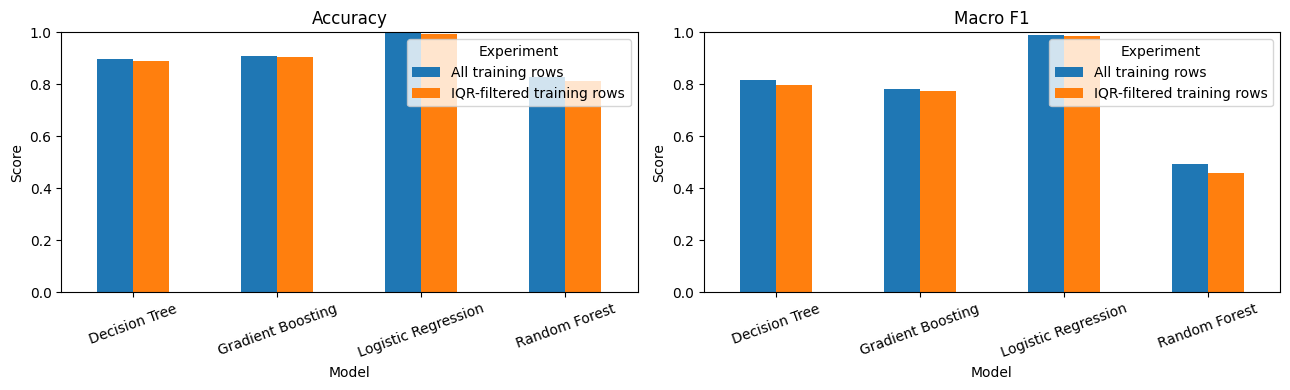

In [8]:
metric_columns = ['Accuracy', 'Balanced accuracy', 'Macro F1', 'Macro ROC-AUC']
comparison = results.pivot(index='Model', columns='Experiment', values=metric_columns)
display(comparison.round(4))
deltas = (results[results['Experiment'] == 'IQR-filtered training rows'].set_index('Model')[metric_columns]
          - results[results['Experiment'] == 'All training rows'].set_index('Model')[metric_columns])
display(deltas.rename(columns=lambda col: f'{col} change').round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for metric, ax in zip(['Accuracy', 'Macro F1'], axes):
    results.pivot(index='Model', columns='Experiment', values=metric).plot.bar(ax=ax, rot=20)
    ax.set(title=metric, ylabel='Score', ylim=(0, 1))
plt.tight_layout()
plt.show()

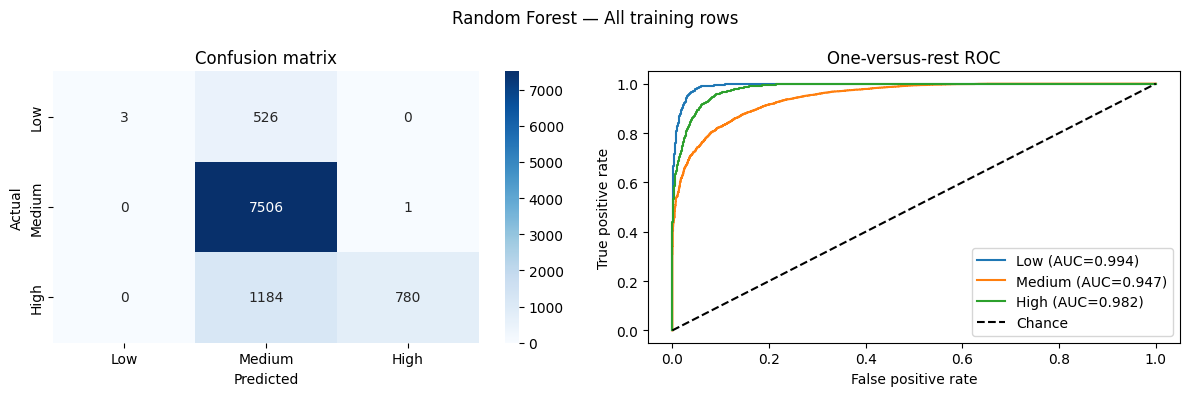

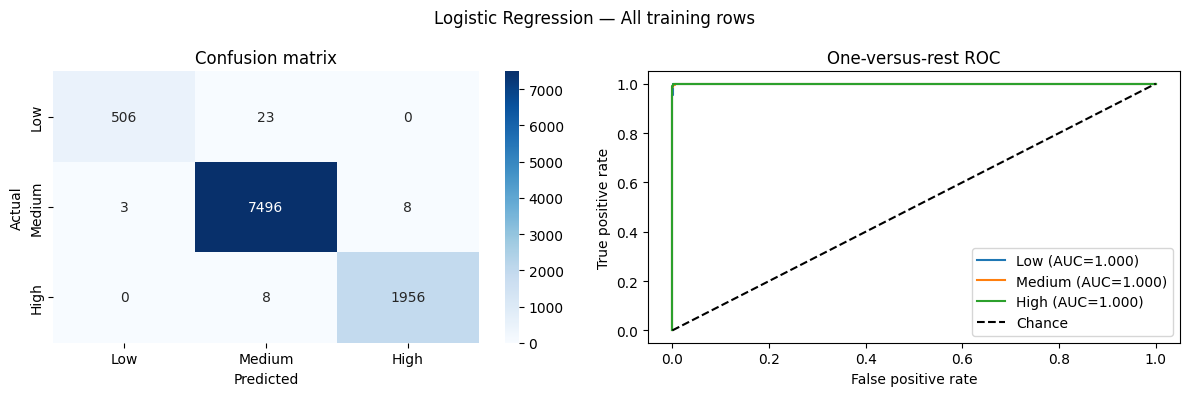

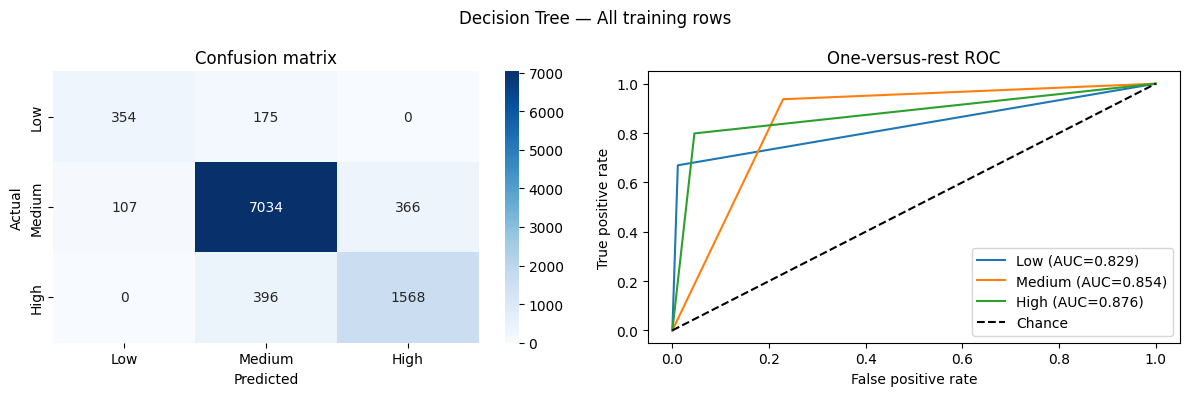

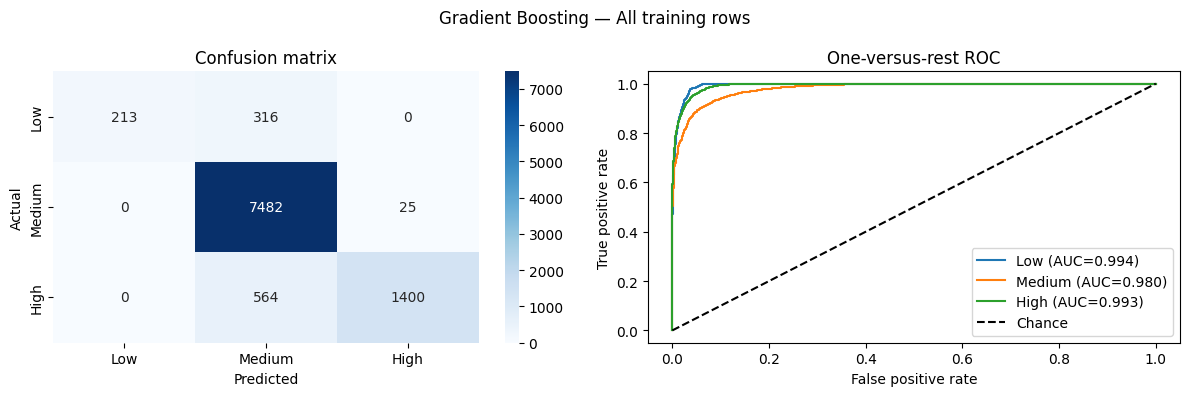

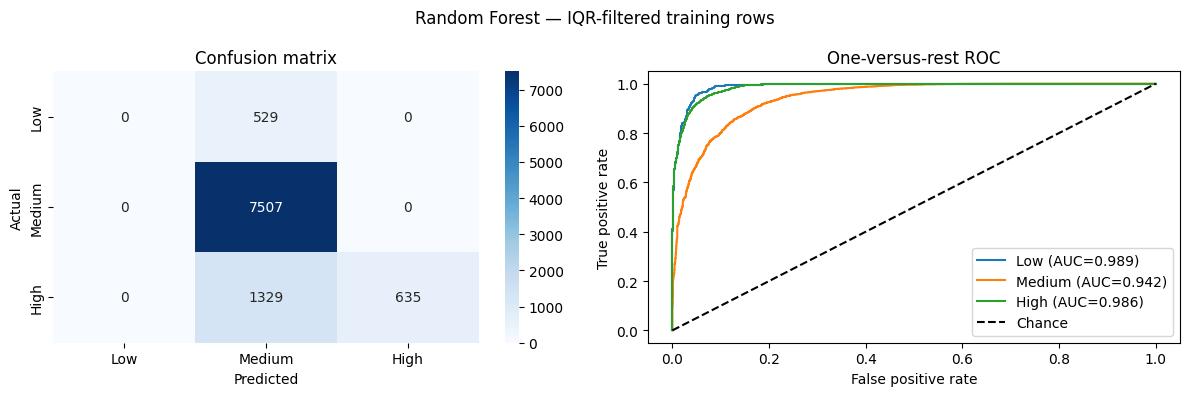

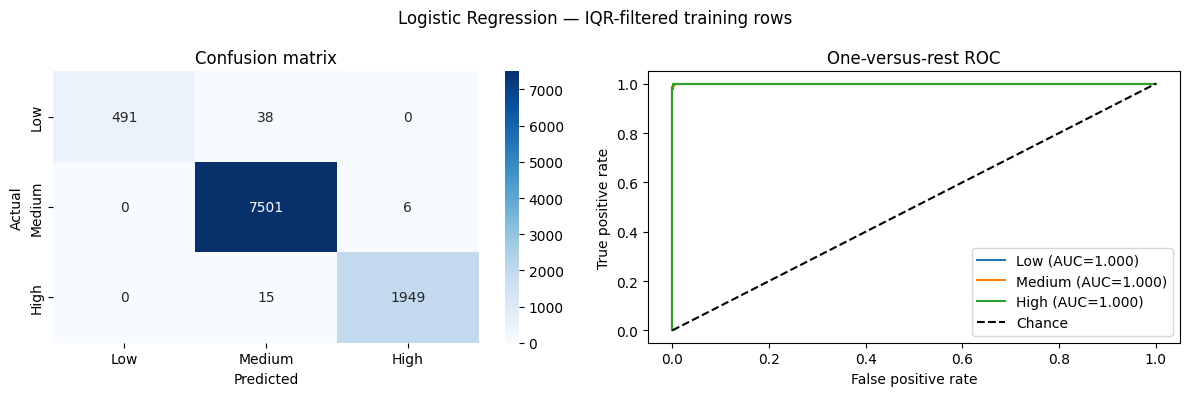

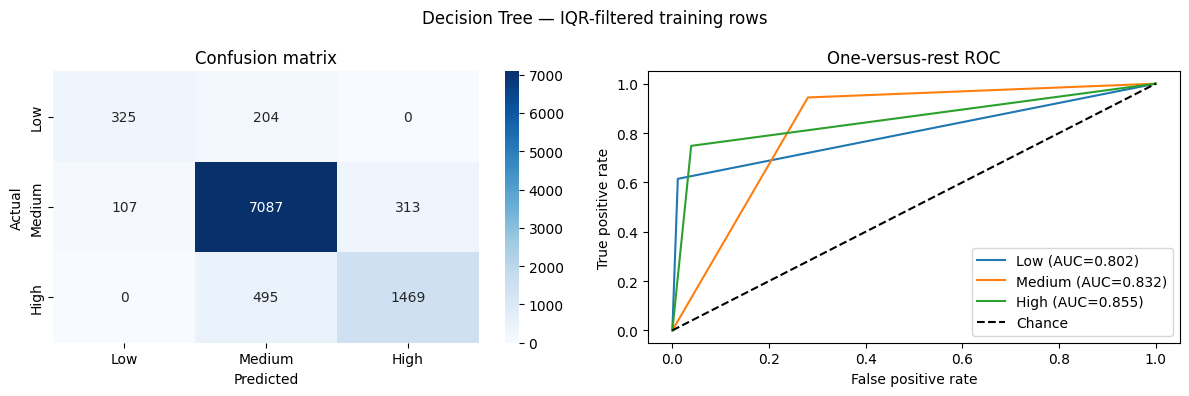

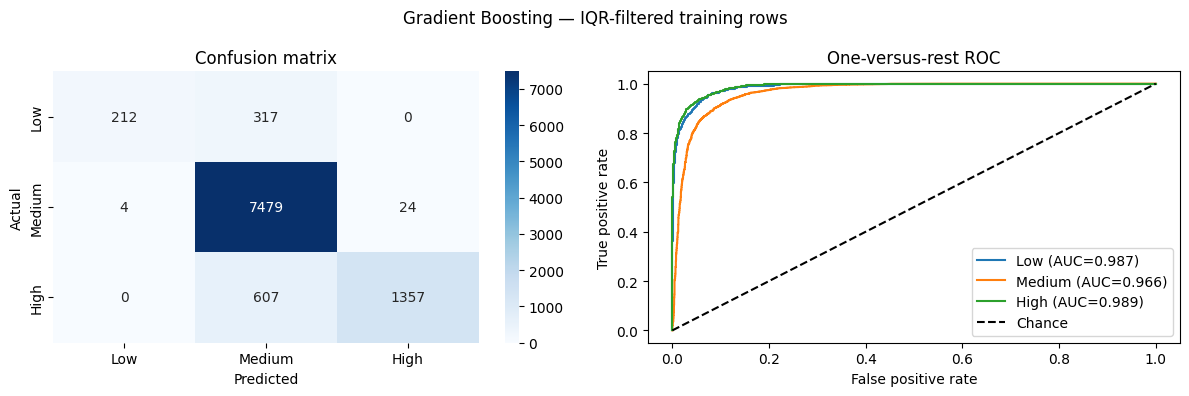

In [9]:
y_test_binary = label_binarize(y_test, classes=CLASSES)
for (experiment, name), model in fitted_models.items():
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.heatmap(confusion_matrix(y_test, predictions, labels=CLASSES),
                annot=True, fmt='d', cmap='Blues', ax=axes[0],
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    axes[0].set(title='Confusion matrix', xlabel='Predicted', ylabel='Actual')
    for i, class_name in enumerate(CLASS_NAMES):
        fpr, tpr, _ = roc_curve(y_test_binary[:, i], probabilities[:, i])
        axes[1].plot(fpr, tpr, label=f'{class_name} (AUC={auc(fpr, tpr):.3f})')
    axes[1].plot([0, 1], [0, 1], 'k--', label='Chance')
    axes[1].set(title='One-versus-rest ROC', xlabel='False positive rate',
                ylabel='True positive rate')
    axes[1].legend(loc='lower right')
    fig.suptitle(f'{name} — {experiment}')
    plt.tight_layout()
    plt.show()

## Interpretation and limitations
- Review macro F1 and per-class recall alongside accuracy: the Medium class may dominate the dataset.
- IQR filtering describes unusual feature values, not confirmed bad records. Rare valid cases can be removed, including minority-class cases.
- Class-wise filtering is confined to training; future predictions require no true severity label. Test data remain unfiltered.
- These results describe one fixed holdout split. They do not establish statistical significance or performance across other datasets.
- Treatment cost and cancer stage may be unavailable at the intended prediction time. They are retained from the original experiment; assess their timing and relationship to the severity score before making predictive claims.
- Check dataset provenance, score construction, duplicates, and repeated patients before interpreting this as clinical evidence. Patient IDs are excluded from predictors; this workflow assumes independent rows.
- Original reported accuracies, including 92.4%, are not carried forward because the evaluation procedure changed. Update the README only with metrics produced by a fresh run of this notebook.